# RappiPlus Project: From Data to Business Decisions

**Introduction**

The goal of this project is to evaluate the performance of the **RappiPlus** service in order to support **data-driven business decisions**.

The analysis draws on multiple business datasets:

* **rappiplus_orders_raw.csv** → order data, prices, discounts, and revenue
* **rappiplus_catalog.csv** → product costs, categories, and suppliers
* **rappiplus_marketing_spend.csv** → marketing spend by channel and country
* **events / users / user_activity (SQL)** → user behavior within the platform
* **experiment_checkout_ui.csv** → results of an A/B test on the checkout

The analysis follows a clear, step-by-step logic:

1. 🔍 Assess whether the data can be trusted (data quality checks in Python)

2. 💰 Analyze whether the business is profitable (revenue, costs, and profit)

3. 🛒 Understand where users drop off (conversion funnel)

4. 🔁 Evaluate whether users come back (cohort retention analysis)

5. 🧪 Validate whether changes have an impact (statistical testing)

6. 📊 Communicate the results (BI dashboard)

Throughout the project, raw data is turned into insights that answer key business questions and support **actionable recommendations**.

---

## 🔹 Step 1: Loading and Validating Data Quality

---

### 1.1 Data Loading and Quick Overview

**🎯 Objective:** Get familiar with the structure of the business datasets before starting the analysis.

**What I did:**

- Imported the required libraries
- Loaded the three source files:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Stored them as DataFrames named `orders`, `catalog`, and `marketing`
- Explored each dataset to understand its structure, columns, and data types

---

In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.display import display

In [2]:
# Load source datasets
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')

In [3]:
# Inspect orders: structure, null values and first rows
orders.info()
display(orders.isna().sum())
display(orders.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  300
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     80
cantidad               50
precio_unitario        50
monto_descuento        50
monto_total             0
dtype: int64

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28
5,order_5,user_2792,2025-04-22,mexico,desktop,organic,Tablet-Standard-64GB,Electronica,1.0,179.34,0.0,179.34
6,order_6,user_2802,2025-03-15,Colombia,mobile,organic,Blender-XL-Red,Hogar,2.0,163.59,0.0,327.19
7,order_7,user_1083,2025-05-01,Mexico,desktop,organic,Tablet-Standard-64GB,Electronica,2.0,373.68,0.0,747.35
8,order_8,user_2352,2025-03-01,Argentina,desktop,paid_search,Laptop-Gaming-16GB,Electronica,2.0,477.27,5.0,949.54
9,order_9,user_7001,2025-05-31,Mexico,mobile,organic,Sneakers-Urban-42,Moda,1.0,339.30,5.0,334.30


In [4]:
# Inspect catalog: structure, null values and first rows
catalog.info()
display(catalog.isna().sum())
display(catalog.head(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


nombre_producto       0
categoria_producto    0
costo_unitario        0
proveedor             0
dtype: int64

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC


In [5]:
# Inspect marketing: structure, null values and first rows
marketing.info()
display(marketing.isna().sum())
display(marketing.head(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01


- **orders:** Convert `fecha_hora_pedido` from object to datetime64. Null values:
    - `pais` → 300
    - `dispositivo` → 20
    - `fuente_referencia` → 30
    - `nombre_producto` → 30
    - `categoria_producto` → 80
    - `cantidad` → 50
    - `precio_unitario` → 50
    - `monto_descuento` → 50
- **catalog:** No issues found.
- **marketing:** Convert `fecha` from object to datetime64. Null values:
    - `canal` → 101

---

### Data Review and Quality Checks

**🎯 Objective:** Detect and fix data issues that could affect the analysis of revenue, costs, and profitability.

**What I plan to do:**

I will review all three datasets, applying the following checks:

- Validate and convert date columns to the correct format
- Check numeric variables for negative values or invalid zeros
- Verify the consistency of monetary amounts
- Remove duplicate records
- Review categorical variables for inconsistencies

---

**REMOVE DUPLICATE RECORDS AND DATE COLUMNS TO CORRECT FORMAT**

In [6]:
# We change "fecha_hora_pedido" from orders and "fecha" from marketing to datetime
orders["fecha_hora_pedido"] = pd.to_datetime(orders["fecha_hora_pedido"], errors="coerce")
marketing["fecha"] = pd.to_datetime(marketing["fecha"], errors="coerce")

In [7]:
# We check the changes
display(marketing.info())
display(orders.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[ns]
 1   pais        1620 non-null   object        
 2   id_campaña  1620 non-null   object        
 3   canal       1519 non-null   object        
 4   gasto       1620 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 63.4+ KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25100 non-null  object        
 1   id_usuario          25100 non-null  object        
 2   fecha_hora_pedido   25100 non-null  datetime64[ns]
 3   pais                24800 non-null  object        
 4   dispositivo         25080 non-null  object        
 5   fuente_referencia   25070 non-null  object        
 6   nombre_producto     25070 non-null  object        
 7   categoria_producto  25020 non-null  object        
 8   cantidad            25050 non-null  float64       
 9   precio_unitario     25050 non-null  float64       
 10  monto_descuento     25050 non-null  float64       
 11  monto_total         25100 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ MB


None

In [8]:
# We check duplicates in orders and marketing
print("Duplicated records in 'orders' dataset =", orders.duplicated().sum())
print("Duplicated records in 'marketing' dataset =", marketing.duplicated().sum())

Duplicated records in 'orders' dataset = 100
Duplicated records in 'marketing' dataset = 0


In [9]:
# We check duplicates by business key

## We set 'id_pedido' as the business key
keys_orders = ["id_pedido"]
keys_marketing = ["id_campaña", "fecha"]

## Duplicated records by business key
print(f"Duplicated records by {keys_orders} in 'orders' dataset =", orders.duplicated(subset=keys_orders).sum())
print(f"Duplicated records by {keys_marketing} in 'marketing' dataset =", marketing.duplicated(subset=keys_marketing).sum())

Duplicated records by ['id_pedido'] in 'orders' dataset = 100
Duplicated records by ['id_campaña', 'fecha'] in 'marketing' dataset = 0


In [10]:
# Elimination of the duplicated records
orders  = orders.drop_duplicates(subset=keys_orders, keep="first").reset_index(drop=True)

# Verify that the changes were applied
print(f"Duplicated records by {keys_orders} in 'orders' dataset after the elimination =", orders.duplicated(subset=keys_orders).sum())

Duplicated records by ['id_pedido'] in 'orders' dataset after the elimination = 0


**CATEGORICAL VARIABLES REVIEW (and name normalization)**

In [11]:
# Check the unique values of each column to detect hidden nulls in the 'orders' dataset
for col in ["pais", "dispositivo", "fuente_referencia", "nombre_producto", "categoria_producto"]:
    display(col, orders[col].unique())

'pais'

array(['Argentina', 'Mexico', 'Colombia', 'mexico', 'colombia',
       'argentina', nan], dtype=object)

'dispositivo'

array(['desktop', 'mobile', nan], dtype=object)

'fuente_referencia'

array(['organic', 'paid_search', 'social', nan], dtype=object)

'nombre_producto'

array(['Jacket-Winter-M', 'Tablet-Standard-64GB', 'Blender-XL-Red',
       'Laptop-Gaming-16GB', 'Sneakers-Urban-42', 'Phone-Pro-128GB',
       'Vacuum-Pro-Black', nan], dtype=object)

'categoria_producto'

array(['Moda', 'Electronica', 'Hogar', nan], dtype=object)

**Findings:** No hidden nulls were found. However, some names were not normalized, so I standardized them.

In [12]:
# Normalize country names in the 'pais' column of the 'orders' dataset
orders["pais"] = orders["pais"].str.strip().str.title()

# Verify that the changes were applied
print(orders["pais"].unique())

['Argentina' 'Mexico' 'Colombia' nan]


In [13]:
# Check the unique values of each column to detect hidden nulls in the 'marketing' dataset
for mark in ["pais", "id_campaña", "canal"]:
    display(mark, marketing[mark].unique())

'pais'

array(['Mexico', 'Colombia', 'Argentina'], dtype=object)

'id_campaña'

array(['organic_Mexico', 'paid_search_Mexico', 'social_Mexico',
       'organic_Colombia', 'paid_search_Colombia', 'social_Colombia',
       'organic_Argentina', 'paid_search_Argentina', 'social_Argentina'],
      dtype=object)

'canal'

array(['organic', 'paid_search', 'social', nan], dtype=object)

**Findings:** No hidden nulls were found either, so I moved on to reviewing the numeric variables.

**NUMERIC VARIABLES REVIEW**

In [14]:
# Check for anomalous outliers in the numeric variables of 'orders'
orders[["cantidad", "precio_unitario", "monto_descuento", "monto_total"]].describe()

,cantidad,precio_unitario,monto_descuento,monto_total
count,24950.000000,24950.000000,24950.000000,2.500000e+04
mean,7.115110,259.374527,4.502605,2.079498e+03
std,296.869961,138.690738,5.224057,9.914760e+04
min,-2.000000,20.030000,0.000000,-4.926500e+02
25%,1.000000,138.470000,0.000000,1.806700e+02
50%,2.000000,258.795000,0.000000,3.418050e+02
75%,2.000000,380.377500,10.000000,5.185800e+02
max,20000.000000,499.960000,15.000000,8.840200e+06


In [15]:
# Check for negative or zero values in the 'orders' dataset
display(orders[(orders["cantidad"] <= 0) | (orders["monto_total"] <= 0)].sort_values("cantidad", ascending=False))

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
267,order_267,user_1087,2025-05-07,NaN,desktop,social,Phone-Pro-128GB,Electronica,-1.0,43.50,5.0,-38.50
268,order_268,user_84,2025-02-19,NaN,desktop,organic,Phone-Pro-128GB,Electronica,-1.0,497.65,5.0,-492.65
269,order_269,user_3323,2025-05-25,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-1.0,423.53,0.0,-423.53
266,order_266,user_7011,2025-03-13,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-2.0,101.31,10.0,-192.62


In [16]:
# Count how many impossible values there are
print("Values greater than 10 units:", (orders["cantidad"] > 10).sum())
print("Quantity counts:\n", orders["cantidad"].value_counts().head(10))

# Inspect them in detail
display(orders[orders["cantidad"] > 10].sort_values("cantidad", ascending=False))

Values greater than 10 units: 10
Quantity counts:
 cantidad
 2.0        12591
 1.0        12345
 10000.0        6
 20000.0        4
-1.0            3
-2.0            1
Name: count, dtype: int64


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
3656,order_3656,user_884,2025-01-01,Argentina,mobile,organic,Laptop-Gaming-16GB,Electronica,20000.0,297.66,0.0,5953200.0
3668,order_3668,user_7270,2025-06-24,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,20000.0,348.31,0.0,6966200.0
3726,order_3726,user_2536,2025-02-12,Colombia,desktop,social,Laptop-Gaming-16GB,Electronica,20000.0,290.85,0.0,5817000.0
3722,order_3722,user_4723,2025-05-09,Argentina,mobile,paid_search,Laptop-Gaming-16GB,Electronica,20000.0,442.01,0.0,8840200.0
3522,order_3522,user_3575,2025-03-29,Argentina,desktop,social,Laptop-Gaming-16GB,Electronica,10000.0,280.55,0.0,2805500.0
3521,order_3521,user_5812,2025-02-03,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,43.14,0.0,431400.0
3586,order_3586,user_3380,2025-02-03,Mexico,mobile,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,490.35,0.0,4903500.0
3643,order_3643,user_4440,2025-01-07,Colombia,desktop,social,Laptop-Gaming-16GB,Electronica,10000.0,238.15,0.0,2381500.0
3689,order_3689,user_6566,2025-06-16,Mexico,desktop,paid_search,Laptop-Gaming-16GB,Electronica,10000.0,87.69,0.0,876900.0
3748,order_3748,user_7096,2025-02-23,Mexico,desktop,organic,Laptop-Gaming-16GB,Electronica,10000.0,336.93,0.0,3369300.0


In [17]:
# Are all the extreme quantities from the same product?
print(orders[orders["cantidad"].isin([10000, 20000])]["nombre_producto"].unique())

# Does that product ALWAYS have absurd quantities, or only sometimes?
display(orders[orders["nombre_producto"] == "Laptop-Gaming-16GB"]["cantidad"].value_counts())

['Laptop-Gaming-16GB']


cantidad
2.0        1430
1.0        1338
10000.0       6
20000.0       4
Name: count, dtype: int64

In [18]:
# Are all the negative quantities from the same product?
print(orders[orders["cantidad"] < 0]["nombre_producto"].unique())

# Does that product ALWAYS have negative quantities, or only sometimes?
display(orders[orders["nombre_producto"] == "Phone-Pro-128GB"]["cantidad"].value_counts())

['Phone-Pro-128GB']


cantidad
 2.0    1407
 1.0    1326
-1.0       3
-2.0       1
Name: count, dtype: int64

**Findings:** I found 14 records with impossible values in `cantidad`: 4 negative values (-1, -2) concentrated in the product `Phone-Pro-128GB`, and 10 extreme values (10000, 20000) concentrated in `Laptop-Gaming-16GB`. In both cases, the values resemble the most common quantities in the dataset (1 and 2), which suggests a data entry error, but there is not enough evidence to reliably reconstruct the original value.

**Decision:** Since there is no information confirming the true value or indicating that these are returns, I treated these records as invalid and excluded them from the clean dataset used for the business analysis (revenue, average ticket, average quantity, etc.) rather than imputing or correcting them.

Before doing so, I will check whether the same issue appears in `marketing` and verify the consistency of monetary amounts, excluding the identified impossible-quantity records.

In [19]:
# Check for anomalous outliers in the numeric variables of 'marketing'
marketing[["gasto"]].describe()

,gasto
count,1620.00000
mean,1772.74292
std,734.43294
min,501.11000
25%,1128.03000
50%,1782.42500
75%,2420.68500
max,2999.36000


**Findings:** No negative values or impossible numbers were found in the `marketing` dataset.

**VERIFICATION OF AMOUNT CONSISTENCY**

In [20]:
# Exclude the 14 records already identified as invalid in the previous step
invalid_condition = (orders["cantidad"] <= 0) | (orders["cantidad"].isin([10000, 20000]))
to_review = orders[~invalid_condition]

# Recalculate the total amount using the expected formula
calculated_total = to_review["cantidad"] * to_review["precio_unitario"] - to_review["monto_descuento"]
difference = calculated_total - to_review["monto_total"]

# Check how large the differences are
print(difference.abs().describe())

count    2.493600e+04
mean     2.499599e-03
std      4.329982e-03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      5.684342e-14
max      1.000000e-02
dtype: float64


In [21]:
# Confirm there are no real inconsistencies (0.01 is just rounding)
inconsistent_rows = to_review[difference.abs() > 0.02]
print("Inconsistencies found:", len(inconsistent_rows))

Inconsistencies found: 0


**Findings:** I validated whether `monto_total` is consistent with the expected business formula, `cantidad × precio_unitario − monto_descuento`, excluding the 14 records already flagged as invalid (negative or extreme quantities) so they would not contaminate the result with a known issue.

The maximum difference between the calculated amount and `monto_total` was $0.01, which is typical of rounding or floating-point error rather than a data entry mistake. Using a tolerance threshold of 0.02, no real inconsistencies were found.

**Conclusion:** `monto_total` is reliable and does not require correction.

**HANDLING NULLS AND IMPOSSIBLE QUANTITIES**

In [22]:
# Filter out the 14 invalid rows (the condition does not touch NaN values)
invalid_condition = (orders["cantidad"] <= 0) | (orders["cantidad"].isin([10000, 20000]))

orders_v1 = orders[~invalid_condition].reset_index(drop=True)

print("Original rows:", len(orders))
print("Rows without invalid quantities:", len(orders_v1))

Original rows: 25000
Rows without invalid quantities: 24986


**MARKETING:** Once the impossible quantities were handled, I moved on to the null values, starting with `marketing`. Here I checked whether the nulls in `canal` are related to the other variables.

In [23]:
# Is there a pattern with 'pais'?
marketing['canal'].isna().groupby(marketing['pais']).mean().sort_values(ascending=False)

pais
Argentina    0.062963
Mexico       0.062963
Colombia     0.061111
Name: canal, dtype: float64

In [24]:
# Is there a pattern with 'id_campaña'?
marketing['canal'].isna().groupby(marketing['id_campaña']).mean().sort_values(ascending=False)

id_campaña
organic_Mexico           0.066667
social_Argentina         0.066667
organic_Argentina        0.061111
paid_search_Argentina    0.061111
organic_Colombia         0.061111
paid_search_Colombia     0.061111
paid_search_Mexico       0.061111
social_Colombia          0.061111
social_Mexico            0.061111
Name: canal, dtype: float64

In [25]:
# Is there a pattern with 'fecha'?
date_pattern = marketing['canal'].isna().groupby(marketing['fecha']).mean().sort_values(ascending=False)
date_pattern[date_pattern == 1.0].sort_index()  # show all dates where 100% of 'canal' values are null

fecha
2025-01-12    1.0
2025-01-13    1.0
2025-01-14    1.0
2025-01-15    1.0
2025-01-16    1.0
2025-01-17    1.0
2025-01-18    1.0
2025-01-19    1.0
2025-01-20    1.0
2025-01-21    1.0
2025-01-22    1.0
Name: canal, dtype: float64

In [26]:
# Use the 'id_campaña' column to impute the nulls in the 'canal' column
for i, row in marketing.iterrows():
    if pd.isna(row['canal']):
        text_to_remove = '_' + row['pais']
        extracted_channel = row['id_campaña'].rsplit(text_to_remove, 1)[0]
        marketing.at[i, 'canal'] = extracted_channel

In [27]:
# Check that the imputation worked and no nulls remain
print("Nulls after imputation:", marketing['canal'].isna().sum())

# Confirm the channels are still the same as before (organic, paid_search, social)
display(marketing['canal'].unique())

Nulls after imputation: 0


array(['organic', 'paid_search', 'social'], dtype=object)

**On the nulls in `marketing`:** This is a case of MAR (Missing at Random): there is a clear pattern showing that `canal` was not recorded for 11 consecutive days, from January 12, 2025 to January 22, 2025, which means the missingness in `canal` depends on the `fecha` variable.

**Null handling:** I chose an imputation strategy based on information already available in other columns of the same dataset, rather than dropping the affected records or filling them with a generic value. The `id_campaña` column follows a consistent naming convention that combines the marketing channel and the country (for example, `organic_Mexico`, `paid_search_Argentina`). Since neither `id_campaña` nor `pais` had null values, I was able to reconstruct each missing channel by extracting it directly from `id_campaña` and removing the country portion. This recovered the true channel value for every affected row, avoiding both information loss (from deleting rows) and bias (from imputing with the mode or an arbitrary value), since the imputed value is exactly the one recorded elsewhere in the dataset itself.

**ORDERS_V1:** Once the nulls in `marketing` were handled, I moved on to the nulls in the `orders` dataset, which is now called `orders_v1` after the impossible quantities were removed a few steps earlier.

In [28]:
# Check how many nulls each column has
(orders_v1.isna().mean().sort_values(ascending=False) * 100).round(2)

pais                  1.18
categoria_producto    0.32
monto_descuento       0.20
precio_unitario       0.20
cantidad              0.20
fuente_referencia     0.12
nombre_producto       0.12
dispositivo           0.08
fecha_hora_pedido     0.00
id_usuario            0.00
id_pedido             0.00
monto_total           0.00
dtype: float64

In [29]:
# Do these columns share the same null records?
cols = ["cantidad", "precio_unitario", "monto_descuento"]
display(orders_v1[cols].isna().all(axis=1).sum())   # Does it return 50?
display(orders_v1[orders_v1[cols].isna().any(axis=1)])  # Inspect those rows

np.int64(50)

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
74,order_74,user_6172,2025-01-15,Argentina,desktop,organic,Sneakers-Urban-42,NaN,NaN,NaN,NaN,595.85
75,order_75,user_6588,2025-06-19,Colombia,mobile,organic,Sneakers-Urban-42,NaN,NaN,NaN,NaN,458.15
76,order_76,user_3193,2025-03-17,Argentina,mobile,paid_search,Laptop-Gaming-16GB,NaN,NaN,NaN,NaN,319.75
77,order_77,user_775,2025-06-24,Argentina,desktop,social,Vacuum-Pro-Black,NaN,NaN,NaN,NaN,227.55
78,order_78,user_2702,2025-03-19,Argentina,desktop,paid_search,Phone-Pro-128GB,NaN,NaN,NaN,NaN,432.39
79,order_79,user_6438,2025-03-22,Colombia,desktop,paid_search,Sneakers-Urban-42,NaN,NaN,NaN,NaN,527.15
80,order_80,user_6790,2025-01-03,Mexico,desktop,organic,Vacuum-Pro-Black,NaN,NaN,NaN,NaN,711.18
81,order_81,user_232,2025-05-16,Mexico,mobile,paid_search,Tablet-Standard-64GB,NaN,NaN,NaN,NaN,41.08
82,order_82,user_5665,2025-02-07,Colombia,mobile,paid_search,Sneakers-Urban-42,NaN,NaN,NaN,NaN,431.55
83,order_83,user_5225,2025-04-25,Argentina,mobile,organic,Sneakers-Urban-42,NaN,NaN,NaN,NaN,279.35


In [30]:
# Are the nulls related to the other columns?
null_cols = orders_v1.columns[orders_v1.isna().any()]
group_cols = ["dispositivo", "fuente_referencia", "categoria_producto", "pais"]

for col in null_cols:
    for g in group_cols:
        if col != g:
            print(f"\nNull rate of {col} by {g}")
            print(
                orders_v1[col].isna().astype(float)
                .groupby(orders_v1[g], dropna=False)
                .mean()
                .round(3)
            )


Null rate of pais by dispositivo
dispositivo
desktop    0.011
mobile     0.013
NaN        0.000
Name: pais, dtype: float64

Null rate of pais by fuente_referencia
fuente_referencia
organic        0.009
paid_search    0.014
social         0.013
NaN            0.000
Name: pais, dtype: float64

Null rate of pais by categoria_producto
categoria_producto
Electronica    0.011
Hogar          0.013
Moda           0.011
NaN            0.000
Name: pais, dtype: float64

Null rate of dispositivo by fuente_referencia
fuente_referencia
organic        0.000
paid_search    0.001
social         0.001
NaN            0.000
Name: dispositivo, dtype: float64

Null rate of dispositivo by categoria_producto
categoria_producto
Electronica    0.001
Hogar          0.001
Moda           0.001
NaN            0.000
Name: dispositivo, dtype: float64

Null rate of dispositivo by pais
pais
Argentina    0.000
Colombia     0.001
Mexico       0.001
NaN          0.000
Name: dispositivo, dtype: float64

Null rate of fuent

In [31]:
n_before = len(orders_v1)                      # store the number of rows at the start (24,986)
orders_v2 = orders_v1.dropna().copy()          # create orders_v2 without any row that has a null value
rows_lost = n_before - len(orders_v2)          # rows removed = before - after
print("Rows lost:", rows_lost)
print("Share of total:", f"{rows_lost / n_before:.2%}")  # expected: 396 rows (1.58%)

Rows lost: 396
Share of total: 1.58%


In [32]:
print("Total revenue before dropping:", orders_v1["monto_total"].sum())
print("Total revenue after dropping:", orders_v2["monto_total"].sum())

Total revenue before dropping: 9643909.559999999
Total revenue after dropping: 9491675.14


In [33]:
print("Average ticket before dropping:", orders_v1["monto_total"].mean())
print("Average ticket after dropping:", orders_v2["monto_total"].mean())

Average ticket before dropping: 385.97252701512843
Average ticket after dropping: 385.9973623424156


**Findings:** I grouped the nulls by co-occurrence. Group A (`cantidad`, `precio_unitario` and `monto_descuento`) shares exactly the same 50 rows, which I confirmed by cross-checking them. These rows also have a null `monto_total` and lack the details needed to reconstruct it, so imputing with the mean or median would rely on assumptions and could bias the data. The remaining nulls are low in volume (at most 1.18% per column) and partially co-occur as well (`fuente_referencia`, `nombre_producto` and `categoria_producto`).

To decide how to handle them, I evaluated how much would be lost by dropping them. In total, 396 rows were removed (1.58%), which reduces total revenue by $152,234 and leaves 98.42% of the records available. The average ticket is practically unchanged (385.97 vs. 386.00), which indicates that the removed rows did not differ from the rest. On the other hand, imputing the categorical variables with "Unknown" would create categories so small compared to the others that they would lose meaning in segmentations and charts.

For these reasons, I decided to drop these records. Their absence does not meaningfully affect the analysis, although absolute revenue figures should be read as a lower bound.

In [34]:
# Remove the null flag columns
orders_v2 = orders_v2.drop(columns=[c for c in orders_v2.columns if c.endswith("_es_nulo")])

In [35]:
# Reset the index
orders_v2 = orders_v2.reset_index(drop=True)

In [36]:
# Verify that everything is correct
print("Shape of the new dataset:", orders_v2.shape)    # expected: (24590, 11)
print("Nulls:", orders_v2.isna().sum().sum())          # expected: 0
print("Original columns:", orders_v2.columns.tolist()) # only the 11 original columns

Shape of the new dataset: (24590, 12)
Nulls: 0
Original columns: ['id_pedido', 'id_usuario', 'fecha_hora_pedido', 'pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto', 'cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']


---
**📦 Export:** Once the cleaning was complete, I exported the cleaned datasets so they could be used in the final stage of the project.

In [37]:
# Export the cleaned datasets
orders_v2.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

---

## 🔹 Step 2: Analyzing Whether the Business Is Profitable

### 2.1 Calculating the Main KPIs

**🎯 Objective:** Calculate the key business indicators to evaluate revenue, costs, and profitability.

For this step, I use the three cleaned datasets (`orders`, `catalog`, and `marketing_spend`):

**📊 Part 1: Business Profitability**
- Calculate the total revenue
- Calculate the total cost
- Determine how much has been invested in marketing
- Assess whether the business is profitable by calculating profit

---

**📈 Part 2: Sales Behavior**
- Calculate the average ticket per order
- Calculate the average number of products per order
- Identify the best-selling product
- Break down marketing spend by channel

In [38]:
# Revenue
print("Total revenue:", orders_v2['monto_total'].sum())

Total revenue: 9491675.14


In [39]:
# Plan a merge to analyze the total cost

## Select the relevant columns from both datasets, orders_v2 and catalog
orders_v2_short = orders_v2[["id_pedido", "fecha_hora_pedido", "nombre_producto", "categoria_producto", "cantidad", "precio_unitario", "monto_descuento", "monto_total"]]
catalog_short = catalog[["nombre_producto", "categoria_producto", "costo_unitario"]]

## Join the datasets
orders_cost = orders_v2.merge(
    catalog[["nombre_producto", "costo_unitario"]],
    on="nombre_producto",
    how="left",
    validate="m:1",
)

## Verify that the join worked correctly
print(len(orders_v2), len(orders_cost))              # should be equal (24590)
print(orders_cost["costo_unitario"].isna().sum())    # expected: 0
print(orders_cost["monto_total"].sum())              # should still be 9,491,675.14

24590 24590
0
9491675.14


In [40]:
# Total cost
orders_cost["total_cost"] = orders_cost["cantidad"] * orders_cost["costo_unitario"]
print("Total cost:", orders_cost["total_cost"].sum())

Total cost: 3783478.8


In [41]:
# Marketing investment
print("Marketing investment:", marketing['gasto'].sum())

Marketing investment: 2871843.53


In [42]:
# Business profitability

## Store the results of the previous calculations in variables
total_revenue = orders_v2['monto_total'].sum()
total_cost = orders_cost["total_cost"].sum()
marketing_spend = marketing['gasto'].sum()

## Calculate profit
profit = total_revenue - total_cost - marketing_spend
print(f"Business profit: {profit:.2f}")

Business profit: 2836352.81


**Part 1: Business Profitability**
- **Total revenue:** \$9,491,675.14
- **Total cost:** \$3,783,478.80
- **Marketing investment:** \$2,871,843.53
- **Business profit:** \$2,836,352.81

In [43]:
# Average ticket per order
average_ticket = orders_v2["monto_total"].mean()
print(f"Average ticket per order: {average_ticket:.2f}")

Average ticket per order: 386.00


In [44]:
# Average number of products per order
average_quantity = orders_v2["cantidad"].mean()
print(f"Average number of products per order: {average_quantity:.2f}")

Average number of products per order: 1.51


In [45]:
# Identify the best-selling product

## Calculate the units sold per product and store them in a variable
units_sold = orders_v2.groupby("nombre_producto")["cantidad"].sum()

## Use that variable to find the best-selling product and how many units it sold
top_product = units_sold.idxmax()
top_units = units_sold.max()

## Print the result
print(f"Best-selling product: {top_product} ({top_units:.0f} units)")

Best-selling product: Vacuum-Pro-Black (6203 units)


In [46]:
# Marketing spend by channel
marketing.groupby("canal")["gasto"].sum().sort_values(ascending=False)

canal
social         976818.37
organic        972650.96
paid_search    922374.20
Name: gasto, dtype: float64

**Part 2: Sales Behavior**
- **Average ticket per order:** \$386.00
- **Average number of products per order:** 1.51
- **Best-selling product:** Vacuum-Pro-Black (6,203 units)
- **Marketing spend by channel:**
    - social: \$976,818.37
    - organic: \$972,650.96
    - paid_search: \$922,374.20

---

## 🔹 Step 3: Understanding Where Users Drop Off (Conversion Funnel)

**🎯 Objective:** Analyze user behavior to identify the stage of the process where users are lost.

⚙️ **Database connection:**
I run the configuration line to connect to the database so I can apply SQL queries on the **events** table.

---

**📊 Part 1: Building the Funnel**
- Determine how many users reach each stage of the funnel
- Calculate the number of unique users per `nombre_evento`
- Order the events according to the user flow

---

**📉 Part 2: Conversion Analysis**
- Calculate the conversion rate between each step of the funnel
- Identify the stage where the largest number of users drop off
- Determine the final conversion rate

In [47]:
import pandas as pd
from sqlalchemy import create_engine

db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [48]:
# Explore the events table
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [49]:
# PART 1: Funnel totals
# ======================

query_totals = '''
SELECT nombre_evento, COUNT(DISTINCT id_usuario)
FROM events
WHERE nombre_evento IN ('first_visit', 'add_to_cart', 'add_payment_info', 'purchase', 'begin_checkout', 'select_item')
GROUP BY nombre_evento
ORDER BY CASE nombre_evento
    WHEN 'first_visit'      THEN 1
    WHEN 'select_item'      THEN 2
    WHEN 'add_to_cart'      THEN 3
    WHEN 'begin_checkout'   THEN 4
    WHEN 'add_payment_info' THEN 5
    WHEN 'purchase'         THEN 6
END;
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,count
0,first_visit,7796
1,select_item,7582
2,add_to_cart,7634
3,begin_checkout,7208
4,add_payment_info,6250
5,purchase,6240


In [50]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''
WITH funnel AS (
    SELECT
        nombre_evento,
        COUNT(DISTINCT id_usuario) AS users,
        CASE nombre_evento
            WHEN 'first_visit'      THEN 1
            WHEN 'select_item'      THEN 2
            WHEN 'add_to_cart'      THEN 3
            WHEN 'begin_checkout'   THEN 4
            WHEN 'add_payment_info' THEN 5
            WHEN 'purchase'         THEN 6
        END AS step_order
    FROM events
    WHERE nombre_evento IN ('first_visit', 'select_item', 'add_to_cart',
                            'begin_checkout', 'add_payment_info', 'purchase')
    GROUP BY nombre_evento
)
SELECT
    step_order,
    nombre_evento,
    users,
    LEAST(100, ROUND(100.0 * users / LAG(users) OVER (ORDER BY step_order), 1)) AS conv_vs_previous,
    GREATEST(0, LAG(users) OVER (ORDER BY step_order) - users) AS users_lost,
    ROUND(100.0 * users / FIRST_VALUE(users) OVER (ORDER BY step_order), 1) AS cumulative_conv
FROM funnel
ORDER BY step_order;
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,step_order,nombre_evento,users,conv_vs_previous,users_lost,cumulative_conv
0,1,first_visit,7796,100.0,0,100.0
1,2,select_item,7582,97.3,214,97.3
2,3,add_to_cart,7634,100.0,0,97.9
3,4,begin_checkout,7208,94.4,426,92.5
4,5,add_payment_info,6250,86.7,958,80.2
5,6,purchase,6240,99.8,10,80.0


**Conversion Funnel Findings**

**Part 1: Building the Funnel**

I counted the number of unique users who triggered each event and ordered them according to the purchase flow: `first_visit` → `select_item` → `add_to_cart` → `begin_checkout` → `add_payment_info` → `purchase`.

| Stage | Unique users |
|---|---|
| first_visit | 7,796 |
| select_item | 7,582 |
| add_to_cart | 7,634 |
| begin_checkout | 7,208 |
| add_payment_info | 6,250 |
| purchase | 6,240 |

**Note on `select_item` and `add_to_cart`:** `add_to_cart` has 52 more users than `select_item` (7,634 vs. 7,582). On closer inspection, 401 users triggered `add_to_cart` without ever triggering `select_item`. In other words, a share of users (5.2% of those who added to cart) reached the cart through a path that does not go through that event, for example a direct link to a product page or an "add" button on a list view. It could also mean the event is not always being tracked. I did not remove these users because they reflect real behavior, not erroneous data. To avoid a conversion rate above 100% at this stage, I capped the value at 100%, which is equivalent to treating it as a stage with no loss.

**Part 2: Conversion Analysis**

**Step-to-step conversion**

| Step | Conversion | Users lost |
|---|---|---|
| first_visit → select_item | 97.3% | 214 |
| select_item → add_to_cart | 100%* | 0 |
| add_to_cart → begin_checkout | 94.4% | 426 |
| begin_checkout → add_payment_info | 86.7% | 958 |
| add_payment_info → purchase | 99.8% | 10 |

*Capped at 100% (see the note above).

**Stage with the largest drop-off:** the step from `begin_checkout` to `add_payment_info` has the biggest loss: 958 users (13.3% of those who started checkout). This is the main bottleneck of the funnel, and the second-largest drop (426 users) happens between `add_to_cart` and `begin_checkout`. Once users enter their payment information, almost all of them complete the purchase (99.8%).

**Final conversion rate:** 80.0% (6,240 of the 7,796 first-time visitors ended up purchasing).

---

## 🔹 Step 4: Evaluating Whether Users Come Back (Cohort Retention)

**🎯 Objective:** Analyze user retention to understand whether users return after signing up.

**Tables**

- `users`
- `user_activity`

---

1. I identify each user's cohort based on their **sign-up month**.

2. I calculate weekly retention: how many users **remain active** in each week after sign-up.
   - `retenido_w1`: users active in week 1
   - `retenido_w2`: users active in week 2
   - `retenido_w3`: users active in week 3

3. I calculate the retention percentage for each week by dividing the retained users by the cohort's initial customers:
   - `semana_1`: percentage of users retained in week 1
   - `semana_2`: percentage of users retained in week 2
   - `semana_3`: percentage of users retained in week 3

I also check that the date column is in the correct format (`DATE`), converting it with `CAST(fecha_registro AS DATE)`.

In [51]:
# Explore the users table
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [52]:
# Explore the user_activity table
# =========================
query_user_activity = '''
SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [53]:
# Cohort retention
# ======================

query_cohort_retention_final = '''
WITH cohorts AS (
    SELECT
        id_usuario,
        DATE_TRUNC('month', CAST(fecha_registro AS DATE)) AS cohort
    FROM users
),
activity AS (
    SELECT
        id_usuario,
        CEIL(dias_despues_registro / 7.0) AS week
    FROM user_activity
    WHERE activo = 1
)
SELECT
    TO_CHAR(c.cohort, 'YYYY-MM') AS cohort,
    COUNT(DISTINCT c.id_usuario) AS initial_users,
    COUNT(DISTINCT CASE WHEN a.week = 1 THEN a.id_usuario END) AS retained_w1,
    COUNT(DISTINCT CASE WHEN a.week = 2 THEN a.id_usuario END) AS retained_w2,
    COUNT(DISTINCT CASE WHEN a.week = 3 THEN a.id_usuario END) AS retained_w3,
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN a.week = 1 THEN a.id_usuario END)
          / COUNT(DISTINCT c.id_usuario), 1) AS week_1,
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN a.week = 2 THEN a.id_usuario END)
          / COUNT(DISTINCT c.id_usuario), 1) AS week_2,
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN a.week = 3 THEN a.id_usuario END)
          / COUNT(DISTINCT c.id_usuario), 1) AS week_3
FROM cohorts c
LEFT JOIN activity a ON a.id_usuario = c.id_usuario
GROUP BY c.cohort
ORDER BY c.cohort;
'''

# Run the query
cohort_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohort_final

,cohort,initial_users,retained_w1,retained_w2,retained_w3,week_1,week_2,week_3
0,2025-01,1627,697,668,656,42.8,41.1,40.3
1,2025-02,1444,611,609,635,42.3,42.2,44.0
2,2025-03,1636,677,705,690,41.4,43.1,42.2
3,2025-04,1606,680,697,663,42.3,43.4,41.3
4,2025-05,1687,695,676,706,41.2,40.1,41.8


**Findings:** Users do come back: in any given week, about 42% of each cohort is active again (the average across the five cohorts is 42.0% in week 1, 42.0% in week 2, and 41.9% in week 3). The most relevant point is stability: retention does not decline from week 1 to week 3, and no cohort (January through May) stands out from the rest, with values between 40% and 44%. The small differences between weeks or cohorts (1-2 points) are consistent with normal variation, so I did not interpret them as an improvement or a deterioration. In other words, there is no evidence that users drop off during the first month, nor that more recent cohorts behave better or worse than earlier ones.

This implies that retention is not the main problem for the business. Combined with the funnel analysis, where the largest loss occurs between starting checkout and entering payment information (13.3%), the priority would be reducing friction in the purchase process. At the same time, roughly 58% of each cohort is not active in a given week, which suggests an opportunity for reactivation. As limitations, the follow-up covers only 4 weeks, the metric measures activity in each week (not cumulative retention), and such flat retention, together with an 80% conversion rate, suggests the data may be synthetic, so it should not be compared against industry benchmarks.

---

## 🔹 Step 5: Validating Whether Changes Have an Impact (Statistical Test)

🎯 **Objective:** Evaluate whether the change in the checkout UI affects the **purchase conversion rate**.

---

1. **Analyze the dataset** `experiment_checkout_ui.csv` to identify the main metric, **conversion**.
   - The **conversion** metric is 1 if the user completed the purchase, 0 if not.
2. **State the statistical hypotheses**
3. **Apply the appropriate statistical test**
4. **Interpret the result**

---
**Statistical hypotheses**
   - **H₀ (null hypothesis):** The purchase conversion rate is the same in both versions. Any difference is due to sampling chance.
   - **H₁ (alternative hypothesis):** The conversion rate differs between the two versions. Some factor influences the purchase decision.

**Statistical test:** Two-proportion Z-test
**Significance level (alpha):** 0.05

In [54]:
# Analyze the dataset before running the test
exp = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')
display(exp.info())
display(exp.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB


None

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


In [55]:
# Number of converted users per variant
conversions = exp.groupby('variante')['convirtio'].sum()

# Total users per variant
totals = exp.groupby('variante')['convirtio'].count()

print("Converted users per group:\n", conversions)
print("\nTotal users per group:\n", totals)

Converted users per group:
 variante
control        779
tratamiento    820
Name: convirtio, dtype: int64

Total users per group:
 variante
control        4965
tratamiento    5035
Name: convirtio, dtype: int64


In [56]:
# Convert the values to list format
successes = [conversions['control'], conversions['tratamiento']]
observations = [totals['control'], totals['tratamiento']]

In [57]:
# Import the test
from statsmodels.stats.proportion import proportions_ztest

# Apply the test
z_stat, p_value = proportions_ztest(successes, observations)

# Display the results
print(f"Z statistic: {z_stat}")
print(f"P-value: {p_value}")

Z statistic: -0.8132782986429474
P-value: 0.41605851639119995


In [58]:
# Interpret the results
alpha = 0.05  # significance threshold
if p_value < alpha:
    print("We reject the null hypothesis: there is evidence of a difference.")
else:
    print("We fail to reject the null hypothesis: there is not enough evidence of a difference.")

We fail to reject the null hypothesis: there is not enough evidence of a difference.


In [59]:
# Get the conversion rate of each group
control_rate = successes[0] / observations[0]
treatment_rate = successes[1] / observations[1]

print(f"Control group conversion rate: {control_rate:.2%}")
print(f"Treatment group conversion rate: {treatment_rate:.2%}")

# Interpret the direction of the results
if control_rate > treatment_rate:
    print(f"\nThe control group has a higher conversion rate (by {control_rate - treatment_rate:.2%}).")
elif treatment_rate > control_rate:
    print(f"\nThe treatment group has a higher conversion rate (by {treatment_rate - control_rate:.2%}).")
else:
    print("\nBoth versions have the same conversion rate.")

Control group conversion rate: 15.69%
Treatment group conversion rate: 16.29%

The treatment group has a higher conversion rate (by 0.60%).


**Findings:** The treatment group shows a conversion rate about 6% higher than the control group. However, the two-proportion Z-test returned a p-value above the 0.05 significance threshold, so I fail to reject the null hypothesis. In other words, there is not enough evidence that the new checkout UI changes the conversion rate, and the observed difference could plausibly be due to sampling chance.

---

## 🔹 Step 6: Communicating the Results (BI Dashboard)

🎯 **Objective:** Build a dashboard that presents the results of the sales, cost, and marketing analysis in a clear, visual way.

I used the cleaned CSVs exported in Step 1 (`orders_clean.csv`, `catalog_clean.csv`, and `marketing_clean.csv`) and built a three-page dashboard in **Power BI**. Dashboard labels are in Spanish.

---

### 1️⃣ Data Model

`orders_clean` is related to `catalog_clean` through `nombre_producto` (many-to-one). Since `orders_clean` and `marketing_clean` share no common key, I connected them through two shared dimension tables: `Dim_Date` (a calendar table, which also enables YTD calculations) and `Dim_Pais`. This way, the month and country filters apply to both fact tables at once.

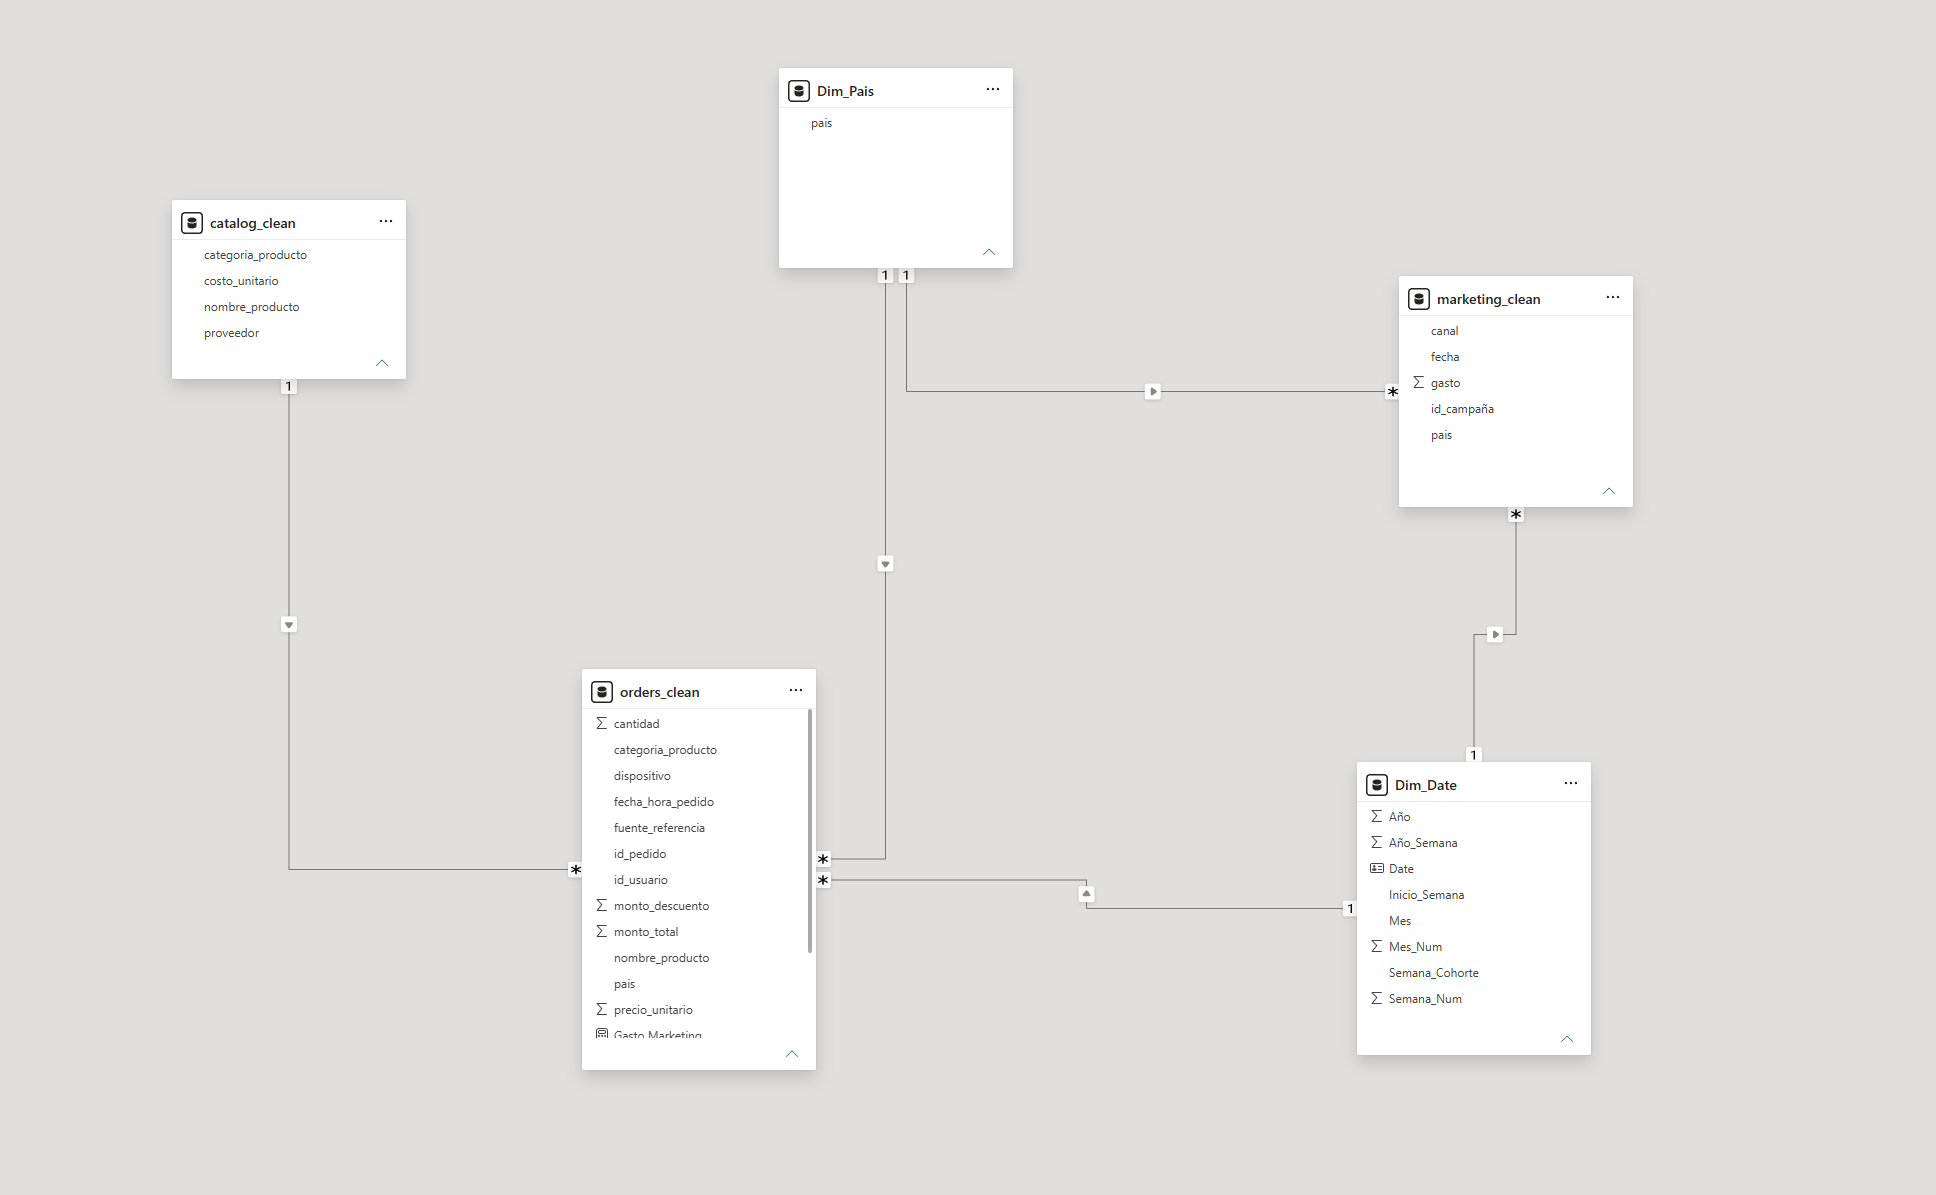

**Note on profit:** In the dashboard, profit is calculated as revenue minus product cost (gross profit, \\$5.71M). Marketing spend cannot be attributed to individual orders or products, because the two tables share no key. The profit after marketing spend (\\$2.84M) is calculated in Step 2.

---

### 2️⃣ Page 1: Executive Overview

A summary of RappiPlus performance in the first half of 2025, with filters by month and country.

- KPI cards: revenue (\\$9.49M), gross profit (\\$5.71M), and marketing spend (\\$2.87M)
- Monthly revenue vs. profit line chart (dual axis)
- Cumulative (YTD) revenue and profit line chart
- Revenue vs. profit by product category

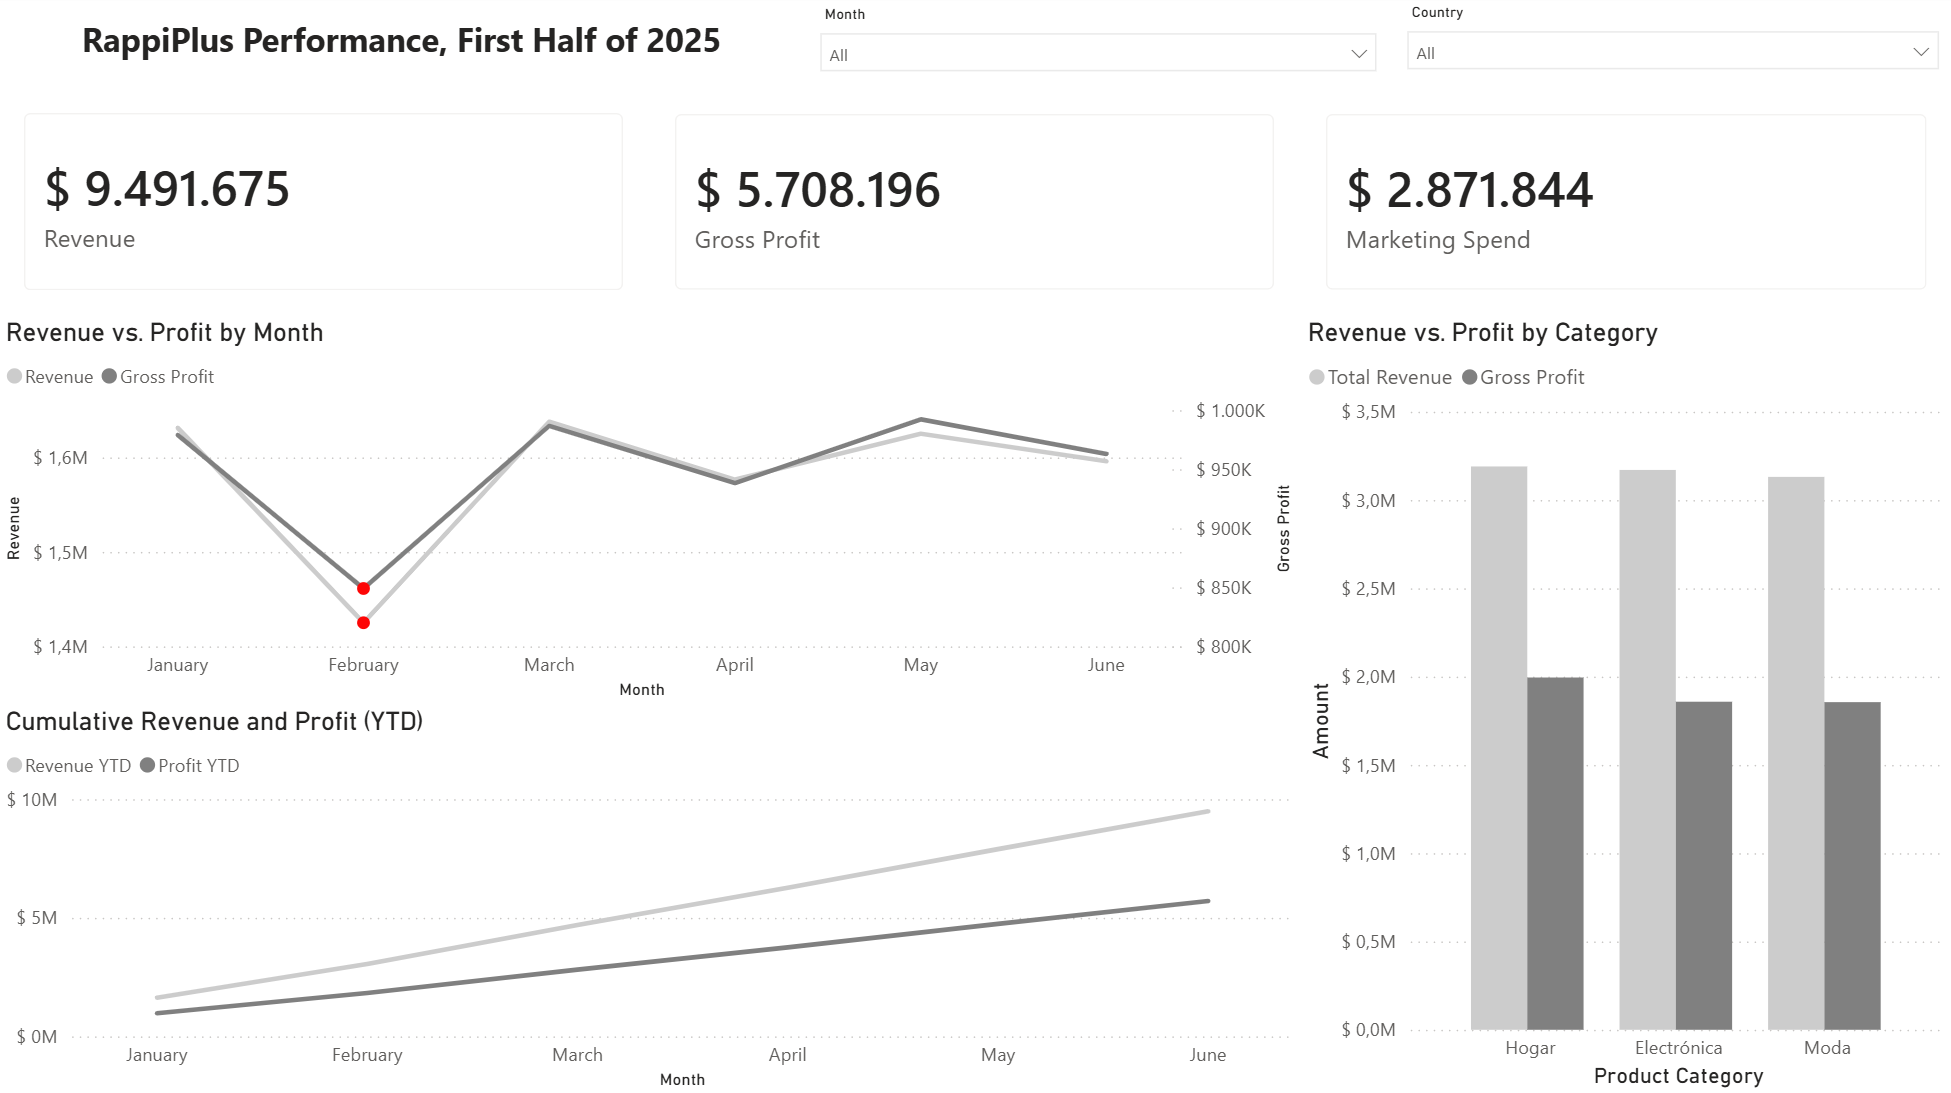

---

### 3️⃣ Page 2: Product Detail

A product-level table (units sold, unit cost, revenue, and profit) with conditional formatting: green for positive profit and red for negative. Below it, a bar chart of units sold by product. Filters by month and product category.

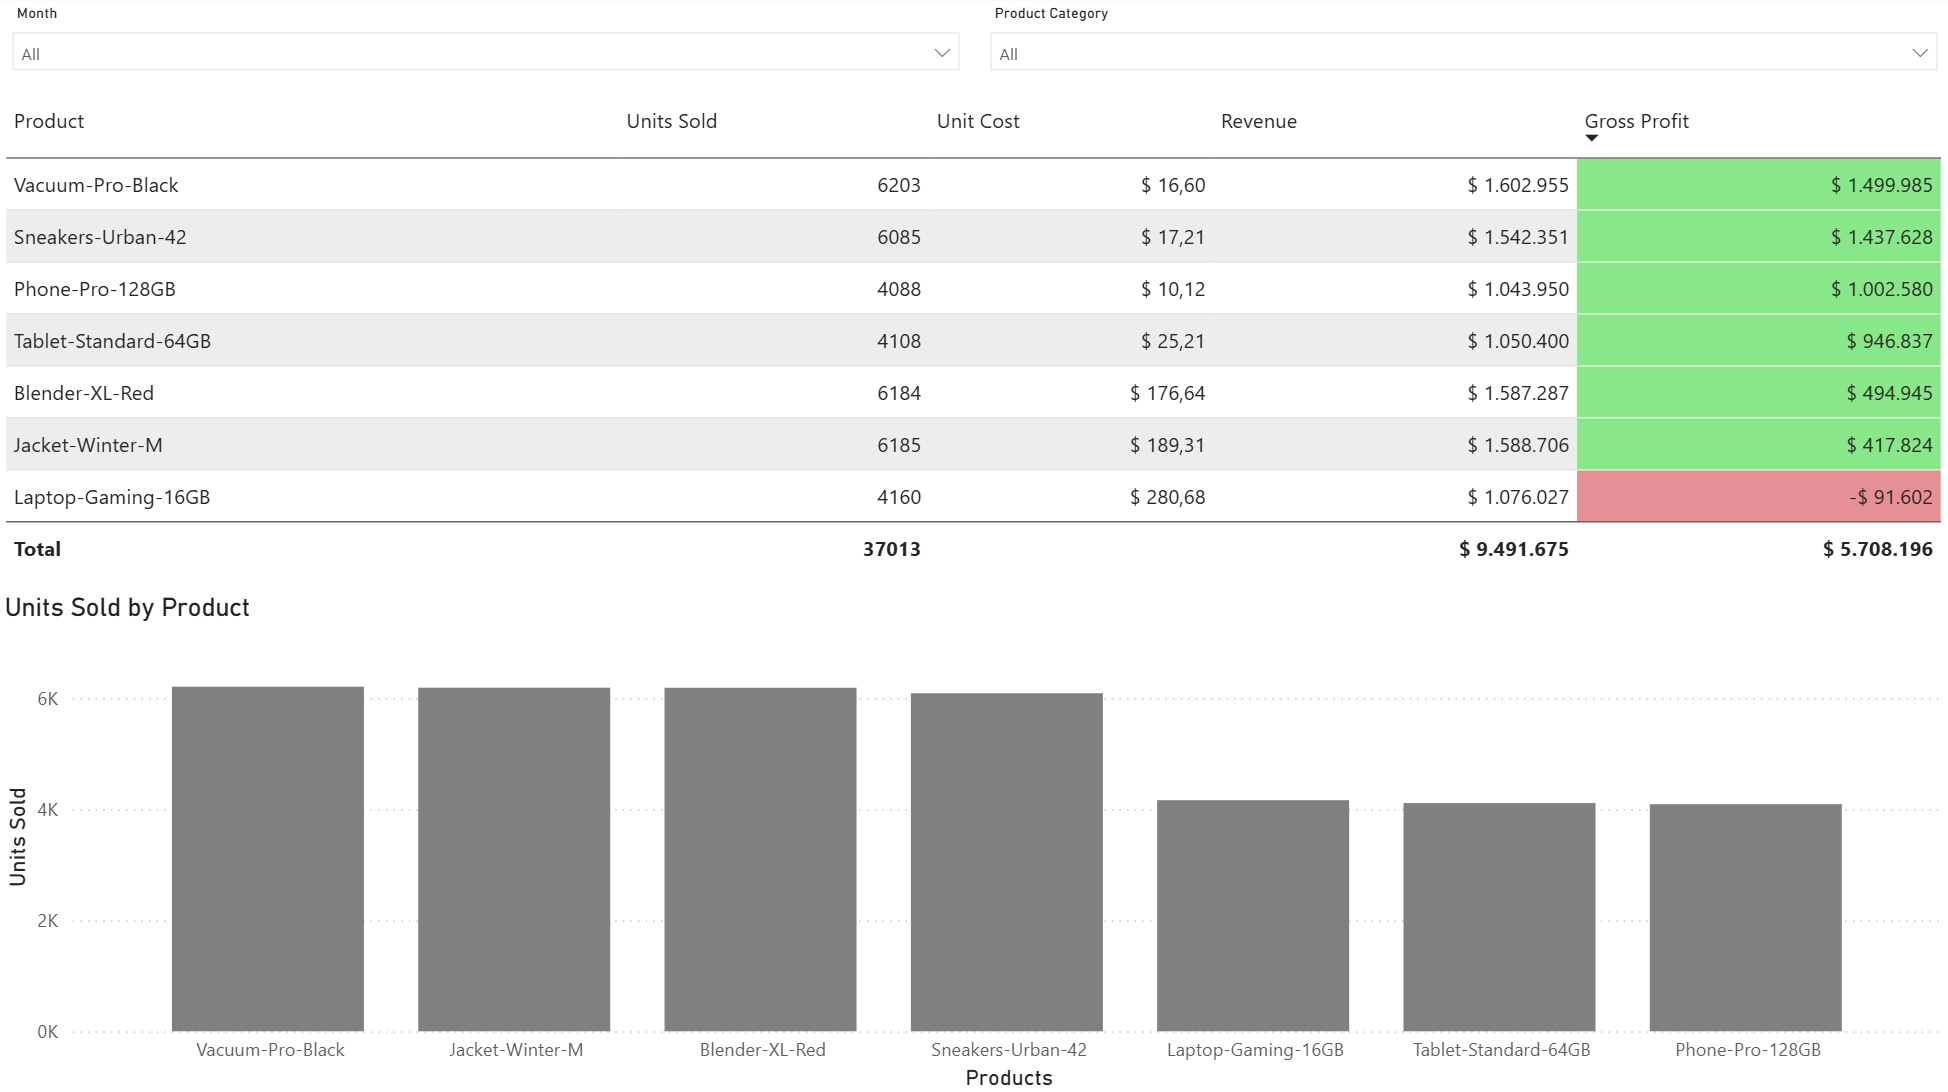

---

### 4️⃣ Page 3: Drill-through by Product

Selecting a product on the previous page opens a table with all of its related orders (order ID, user ID, date, country, device, source, units, unit price, discount, and total), with a back button to return.

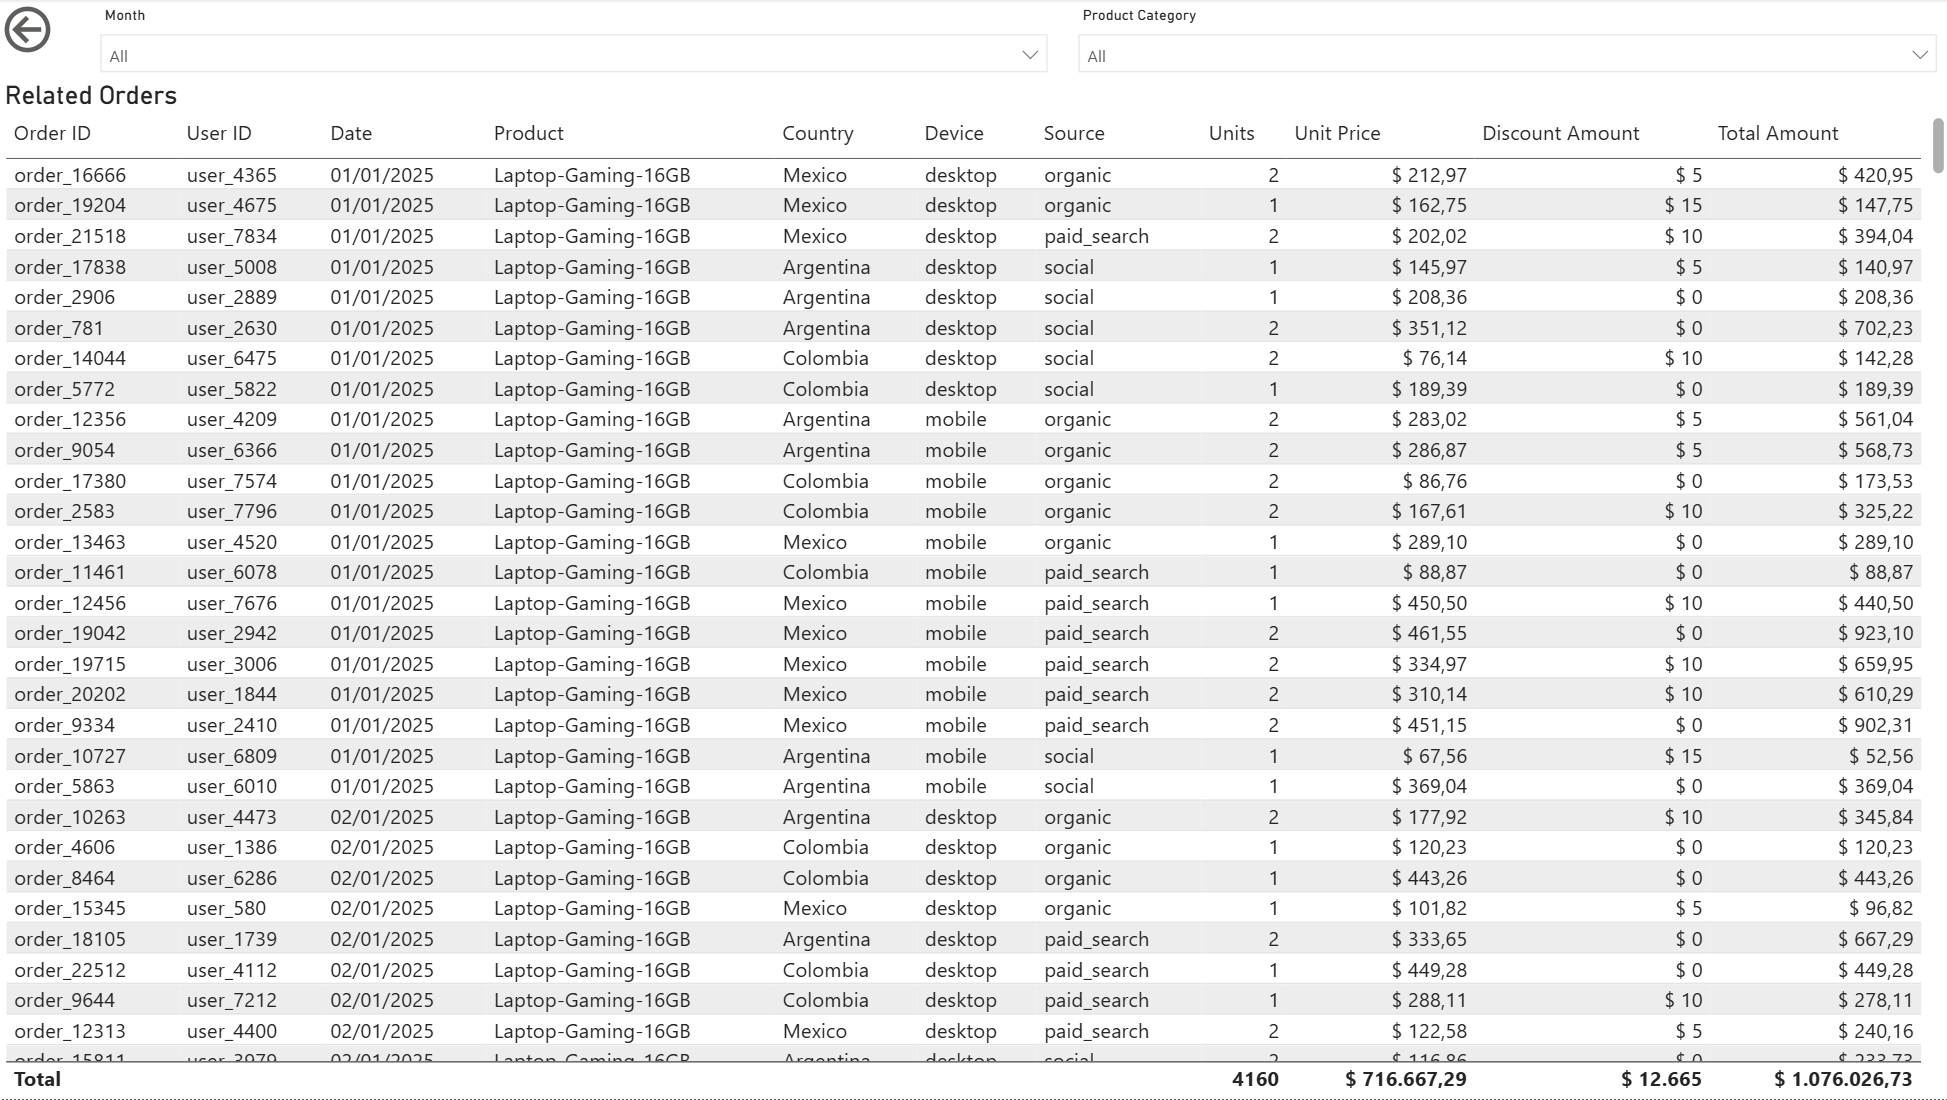

---

### 🔍 Findings

1. **February was the weakest month.** Both revenue and profit dropped sharply compared to the rest of the months, the largest decline of the period. Both recovered in March.
2. **Cumulative growth is steady.** The YTD revenue and profit lines rise consistently through the semester, so the February dip did not change the overall trend.
3. **`Laptop-Gaming-16GB` is the only product with negative profit** (\\$-91,602), despite generating \\$1.08M in revenue.
4. **Low sales volume does not explain the loss.** `Laptop-Gaming-16GB`, `Tablet-Standard-64GB`, and `Phone-Pro-128GB` are the three least-sold products, but the tablet and the phone are profitable. The laptop's problem is margin, not volume.
5. **High-volume products show modest profit.** `Blender-XL-Red` and `Jacket-Winter-M` sell in large quantities and are profitable, but each stays below $500K in profit, which is low compared to the other high-volume products.

The rest of the indicators (category performance, marketing spend by channel) behave in a relatively uniform way.

**Recommendation:** Review the pricing and cost of `Laptop-Gaming-16GB`, since it sells at a loss, and the margins of `Blender-XL-Red` and `Jacket-Winter-M`, which have room for improvement given their volume.

---

**DASHBOARD:** https://drive.google.com/drive/folders/1grJvasIySX-e9YTPZEc3mr-li27VGpM-?usp=drive_link